# 第五組：特徵重新設計（27 個候選 + v3 新增大盤 HMM → 篩選）

第一輪（03、05）的結論：真正有排名資訊的是「波動」與「區間」兩類；報酬、均線、量比幾乎沒有；
幾組特徵彼此重複（Volume_Ratio 與 Turnover ρ=0.996、MA_Gap_20 與 RSI ρ=0.91）。本 notebook 依波動預測文獻
補上缺的幾類資訊，再用**事先寫好的規則**篩選。

**時間紀律**：篩選只用 2016-11～2020 的資料（標籤在 2020 年底前結束）；2021 年只拿來比較新舊特徵組；
2022 之後的驗證期與 2025 之後的封存期**完全不碰**。封存期已經正式使用過一次，新特徵組若之後在封存期評估，
報告必須標註為「事後評估」。

In [1]:
from nb_utils import *                                       # 共用工具
from features_v2 import stock_features, calendar_features, CANDIDATES  # 第二版特徵
from statsmodels.stats.multitest import multipletests        # BH 校正
from scipy import stats                                      # 統計檢定
style()                                                      # 圖表樣式
SCREEN_END = pd.Timestamp("2020-12-31")                      # 篩選資料的終點（標籤需在此前結束）
COMP = ("2021-01-01", "2021-12-31")                          # 新舊特徵組比較期間
panel = pd.read_parquet(PROC / "panel.parquet").sort_values(["sid", "date"])  # 清理後日資料
panel["avolume"] = (panel.volume / panel.adj).where(panel.valid); panel["amount"] = panel.amount.where(panel.valid)  # 還原量、無效日空值
b = panel[panel.sid == BM].set_index("date")                 # 0050
rm = np.log(b.aclose / b.aclose.shift(1))                    # 0050 日報酬
cal = pd.DatetimeIndex(sorted(panel.date.unique()))          # 交易日曆

## A. 舊 15 項 → 新組合的對照
| 文件特徵 | 處理 | 理由（第一輪證據） |
|---|---|---|
| Volatility_5 / _20 | 保留（rv5、rv20） | IC 0.33／0.39，三年同向 |
| Volatility_10 | 改為 rv60 | 跟 5、20 日 ρ>0.8；改補 HAR 的長期（季）成分 |
| Return_1 | 改為 rv1（取絕對值） | 有方向的報酬沒有資訊，絕對值才是波動的日成分 |
| Return_5 / MA_Gap_5 | 刪除 | 只在重疊樣本顯著，一週內排名就洗牌 |
| Return_20 | 保留 | 槓桿效應：下跌後波動上升 |
| High_Low_Range | 保留，另加 Parkinson、Yang–Zhang | 區間比收盤價更能估波動 |
| Close_Open_Range | 改為隔夜波動 on20 | 方向沒資訊；標籤是開盤到開盤，含隔夜跳空 |
| MA_Gap_20 | 保留；RSI_14 刪除 | 兩者 ρ=0.91，留一個 |
| Volume_Ratio | 刪除；保留 Turnover（amt_ratio） | 兩者 ρ=0.996 |
| Volume_Volatility | 保留 | IC 0.15，三年同向 |
| ATR_14 | 保留（除以股價） | 第一名 |
| 新增 | oo20、semi_down20、maxabs20、term5_60、volvol20、garch_fc5、beta60、idio60、rv20_rank、mkt_rv20、log_adv20、amihud20、rev_days、holiday_gap | 見下表 |

In [2]:
rows = []                                                    # 收集各檔特徵
for sid, g in panel[panel.sid.isin(STK)].groupby("sid"):     # 逐檔
    g = g.set_index("date"); rows.append(stock_features(g, rm.reindex(g.index)).assign(sid=sid).reset_index())  # 計算
X = pd.concat(rows)                                          # 合併
X = X.merge(pd.read_parquet(PROC / "garch_features.parquet")[["date", "sid", "garch_fc5"]], on=["date", "sid"], how="left")  # GARCH（04 的 walk-forward 結果）
X = X.merge(pd.DataFrame({"date": rm.index, "mkt_rv20": np.sqrt(252 / 20 * (rm ** 2).rolling(20, min_periods=20).sum()).values}), on="date", how="left")  # 0050 的 20 日波動（市場層級）
X = X.merge(calendar_features(cal, H), on="date", how="left")  # 行事曆特徵
X = X.merge(pd.read_parquet(PROC / "features_v2.parquet", columns=["date", "hmm_stress"]).drop_duplicates("date"), on="date", how="left")  # 大盤 HMM 壓力機率（v3 新增候選；src/hmm_regime.py 走勢前進、濾波）
smp = pd.read_parquet(PROC / "samples.parquet")[["date", "sid", "y", "label_end", "is_decision", "eligible", "hv20_L20"]]  # 標籤
X = X.merge(smp, on=["date", "sid"], how="inner")            # 合併標籤
X = X[X.eligible].copy()                                     # 只用合格列
X["rv20_rank"] = X.groupby("date").rv20.rank(pct=True)       # 當日在合格股票中的波動百分位
FE = list(CANDIDATES); DL = [f for f, (_, d) in CANDIDATES.items() if d]; SL = [f for f in FE if f not in DL]  # 全部／市場層級／個股層級
assert np.allclose(X.rv20, X.hv20_L20, equal_nan=True), "rv20 與第一版 Volatility_20 不一致"  # 一致性檢查
print(f"候選 {len(FE)} 項（個股層級 {len(SL)}、市場層級 {len(DL)}）；覆蓋率最低 {X[X.date >= CFG['data']['study_start']][FE].notna().mean().min():.1%}")  # 印出
display(pd.DataFrame([(f, *CANDIDATES[f]) for f in FE], columns=["特徵", "家族", "每日同值（市場層級）"]))  # 顯示

候選 28 項（個股層級 24、市場層級 4）；覆蓋率最低 85.0%


,特徵,家族,每日同值（市場層級）
0,rv1,A 波動水準,False
1,rv5,A 波動水準,False
2,rv20,A 波動水準,False
3,rv60,A 波動水準,False
4,oo20,A 波動水準,False
5,hl,B 區間估計,False
6,park20,B 區間估計,False
7,yz20,B 區間估計,False
8,atr_p,B 區間估計,False
9,on20,C 隔夜,False


## B. 事先寫定的選取規則（看結果之前）
1. **錨點**：rv20 一定保留（它就是 HV20 基準）。
2. **個股層級**：只用決策日（不重疊）算 IC；保留條件是「IC 通過 BH（q<0.05）且 2017–2020 每年同方向比例 ≥ 75%」
   **或**「扣掉 rv20 後的增量 IC 顯著（HAC 20 日，p<0.05）」。
3. **冗餘**：|ρ| > 0.9 的同一群只留決策日 |IC| 最高者。
4. **市場層級**（每天所有股票同值，沒有橫斷面 IC）：用每個決策日的「平均實際波動」做時間序列檢定，
   控制平均 rv20 後的偏相關 p<0.05 才保留。
5. 總數上限 30。

In [3]:
S = X[(X.date >= CFG["data"]["study_start"]) & X.y.notna() & (X.label_end <= SCREEN_END)].copy()  # 篩選資料（2016-11～2020）
D = S[S.is_decision]                                         # 決策日
print(f"篩選資料：{len(S):,} 列、{S.date.nunique()} 個交易日、{D.date.nunique()} 個決策日（{S.date.min().date()}～{S.date.max().date()}）")  # 印出
def resid_rank(t, f):                                        # 定義：每日把特徵排名對 rv20 排名回歸，取殘差
    a, b = t[f].rank(), t.rv20.rank(); v = b.var()           # 兩個排名
    return a - (np.cov(a, b)[0, 1] / v if v > 0 else 0) * b  # 殘差
R = []                                                       # 收集
for f in SL:                                                 # 個股層級
    icd = ic_by_date(D, f, min_n=8); h = hac_stats(icd, 1)   # 決策日 IC
    icy = ic_by_date(S, f, min_n=8); h20 = hac_stats(icy, 20)  # 每日 IC（頻寬 20）
    yr = icd.groupby(icd.index.year).mean(); yr = yr[yr.index >= 2017]  # 2017–2020 各年
    if f == "rv20": inc = {"ic_mean": np.nan, "hac_p": np.nan}  # 錨點不算增量
    else:
        t = S[["date", f, "rv20", "y"]].dropna(); t["res"] = t.groupby("date", group_keys=False).apply(lambda x: resid_rank(x, f), include_groups=False)  # 殘差
        inc = hac_stats(ic_by_date(t, "res", min_n=8), 20)   # 增量 IC
    R.append({"feature": f, "family": CANDIDATES[f][0], "ic_dec": h["ic_mean"], "p_dec": h["hac_p"], "ic_daily": h20["ic_mean"], "t_daily_h20": h20["hac_t"],
              "sign_years": (np.sign(yr) == np.sign(h["ic_mean"])).mean(), "inc_ic": inc["ic_mean"], "inc_p": inc["hac_p"], "coverage": S[f].notna().mean()})  # 記錄
R = pd.DataFrame(R).set_index("feature")                     # 轉表
R["bh_dec"] = multipletests(R.p_dec, alpha=0.05, method="fdr_bh")[0]  # BH
for f in DL:                                                 # 市場層級
    m = D.groupby("date")[[f, "y", "rv20"]].mean().dropna()  # 每決策日平均
    r1 = m[f].corr(m.y); e1 = np.polyfit(m.rv20, m[f], 1); e2 = np.polyfit(m.rv20, m.y, 1)  # 時間序列相關；控制 rv20
    pr = np.corrcoef(m[f] - np.polyval(e1, m.rv20), m.y - np.polyval(e2, m.rv20))[0, 1]  # 偏相關
    pp = 2 * (1 - stats.t.cdf(abs(pr) * np.sqrt((len(m) - 3) / (1 - pr ** 2)), len(m) - 3))  # 偏相關 p 值
    R.loc[f, ["family", "ts_corr", "ts_partial", "ts_partial_p", "coverage"]] = [CANDIDATES[f][0], r1, pr, pp, S[f].notna().mean()]  # 記錄
display(R.sort_values("ic_dec", key=abs, ascending=False).round(3))  # 顯示

篩選資料：12,349 列、1018 個交易日、204 個決策日（2016-11-01～2020-12-23）


/usr/local/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


/usr/local/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


/usr/local/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


/usr/local/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


/usr/local/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


/usr/local/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


/usr/local/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


/home/claude/mlqt_group5/src/common.py:19: RuntimeWarning: Mean of empty slice
  n = len(x); m = x.mean(); e = x - m                      # 樣本數、平均、離差
/usr/local/lib/python3.13/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/home/claude/mlqt_group5/src/common.py:21: RuntimeWarning: invalid value encountered in scalar divide
  s = e @ e / n                                            # 變異數（第 0 期）
/home/claude/mlqt_group5/src/common.py:24: RuntimeWarning: invalid value encountered in scalar divide
  s += 2 * w * (e[l:] @ e[:-l]) / n                    # 加權共變異


,family,ic_dec,p_dec,ic_daily,t_daily_h20,sign_years,inc_ic,inc_p,coverage,bh_dec,ts_corr,ts_partial,ts_partial_p
feature,,,,,,,,,,,,,
park20,B 區間估計,0.466,0.000,0.465,19.643,1.00,0.196,0.000,1.000,True,NaN,NaN,NaN
atr_p,B 區間估計,0.463,0.000,0.457,20.381,1.00,0.195,0.000,1.000,True,NaN,NaN,NaN
rv60,A 波動水準,0.451,0.000,0.449,18.277,1.00,0.201,0.000,0.964,True,NaN,NaN,NaN
yz20,B 區間估計,0.445,0.000,0.444,18.077,1.00,0.191,0.000,1.000,True,NaN,NaN,NaN
idio60,F 市場,0.444,0.000,0.442,18.384,1.00,0.205,0.000,0.964,True,NaN,NaN,NaN
oo20,A 波動水準,0.437,0.000,0.427,15.910,1.00,0.172,0.000,1.000,True,NaN,NaN,NaN
rv20,A 波動水準,0.427,0.000,0.426,17.146,1.00,NaN,NaN,1.000,True,NaN,NaN,NaN
rv20_rank,F 市場,0.427,0.000,0.426,17.146,1.00,NaN,NaN,1.000,True,NaN,NaN,NaN
garch_fc5,E 波動動態,0.379,0.000,0.390,15.571,1.00,0.169,0.000,0.837,True,NaN,NaN,NaN


## C. 冗餘：|ρ| > 0.9 的群組

In [4]:
cm = D[SL].rank().corr().abs()                               # 決策日上的 |Spearman|
groups, seen = [], set()                                     # 收集群組
for f in R.loc[SL].ic_dec.abs().sort_values(ascending=False).index:  # 依 |IC| 由大到小
    if f in seen: continue                                   # 已被分到別群
    grp = [g for g in SL if g not in seen and cm.loc[f, g] > 0.9]  # 與它 |ρ|>0.9 的特徵
    seen |= set(grp); groups.append(grp)                     # 記錄
display(pd.DataFrame({"代表（|IC| 最高）": [g[0] for g in groups], "同群其他": [", ".join(g[1:]) for g in groups]}))  # 顯示

,代表（|IC| 最高）,同群其他
0,park20,"yz20, atr_p"
1,rv60,idio60
2,rv20,oo20
3,rv20_rank,
4,garch_fc5,
5,maxabs20,
6,hl,
7,rv5,
8,semi_down20,
9,on20,


## D. 套用規則

In [5]:
keep, why = [], {}                                           # 保留清單與理由
for grp in groups:                                           # 逐群
    rep = "rv20" if "rv20" in grp else grp[0]                # 有錨點就以錨點代表
    r = R.loc[rep]                                           # 代表的統計
    if rep == "rv20": keep.append(rep); why[rep] = "錨點（HV20 基準）"; continue  # 規則 1
    a = bool(r.bh_dec) and r.sign_years >= 0.75              # 規則 2a
    bb = (r.inc_p < 0.05)                                    # 規則 2b
    if a or bb: keep.append(rep); why[rep] = ("BH 顯著且各年同向" if a else "") + ("；" if a and bb else "") + ("對 rv20 有增量" if bb else "")  # 保留
    for o in grp[1:]: why[o] = f"與 {rep} 重複（|ρ|>0.9）"     # 同群其他標註
for f in DL:                                                 # 規則 4
    if R.loc[f, "ts_partial_p"] < 0.05: keep.append(f); why[f] = "控制 rv20 後時間序列仍顯著"  # 保留
for f in R.index:                                            # 其餘標註
    why.setdefault(f, "未達規則")                             # 未保留原因
R["keep"] = R.index.isin(keep); R["reason"] = pd.Series(why)  # 寫入
keep = keep[:30]                                             # 上限 30
print(f"保留 {len(keep)} 項：", ", ".join(keep))              # 印出
display(R[["family", "ic_dec", "inc_ic", "inc_p", "sign_years", "ts_partial", "ts_partial_p", "keep", "reason"]].sort_values(["keep", "family"], ascending=[False, True]).round(3))  # 顯示

保留 18 項： park20, rv60, rv20, rv20_rank, garch_fc5, maxabs20, hl, rv5, semi_down20, on20, log_adv20, rv1, vol_cv, term5_60, ma20_dist, ret20, amt_ratio, holiday_gap


,family,ic_dec,inc_ic,inc_p,sign_years,ts_partial,ts_partial_p,keep,reason
feature,,,,,,,,,
rv1,A 波動水準,0.192,0.075,0.000,1.00,NaN,NaN,True,BH 顯著且各年同向；對 rv20 有增量
rv5,A 波動水準,0.345,0.105,0.000,1.00,NaN,NaN,True,BH 顯著且各年同向；對 rv20 有增量
rv20,A 波動水準,0.427,NaN,NaN,1.00,NaN,NaN,True,錨點（HV20 基準）
rv60,A 波動水準,0.451,0.201,0.000,1.00,NaN,NaN,True,BH 顯著且各年同向；對 rv20 有增量
hl,B 區間估計,0.360,0.159,0.000,1.00,NaN,NaN,True,BH 顯著且各年同向；對 rv20 有增量
park20,B 區間估計,0.466,0.196,0.000,1.00,NaN,NaN,True,BH 顯著且各年同向；對 rv20 有增量
on20,C 隔夜,0.309,0.073,0.000,1.00,NaN,NaN,True,BH 顯著且各年同向；對 rv20 有增量
semi_down20,D 不對稱尾部,0.342,0.077,0.001,1.00,NaN,NaN,True,BH 顯著且各年同向；對 rv20 有增量
ret20,D 不對稱尾部,0.080,0.009,0.668,0.75,NaN,NaN,True,BH 顯著且各年同向


## E. 2021 年比較：舊 15 項 vs 新組合 vs 全部 27 項
訓練 2016-11～2020（標籤在 2021 年前結束），預測 2021 年決策日。模型與參數沿用 05_validate 選出的設定，不重新調參。

In [6]:
from models import make_model, FLOOR                         # 模型工具
from strategies import parse                                 # 設定名稱解析
SEL = pd.read_csv(TAB / "selected_configs.csv", index_col=0).config  # 選定設定
old = pd.read_parquet(PROC / "samples.parquet")[["date", "sid"] + [c for c in pd.read_parquet(PROC / "samples.parquet").columns if c.endswith("_L20")]]  # 舊 15 項
Z = X.merge(old, on=["date", "sid"], how="left", suffixes=("", "_old"))  # 合併
OLD = [c for c in Z.columns if c.endswith("_L20")]           # 舊特徵欄
tr = Z[(Z.date >= CFG["data"]["study_start"]) & Z.y.notna() & (Z.label_end < pd.Timestamp(COMP[0]))]  # 訓練（含 purge）
te = Z[Z.is_decision & Z.y.notna() & (Z.date >= COMP[0]) & (Z.date <= COMP[1])]  # 2021 決策日
def score(p):                                                # 定義：評估指標
    t = te.assign(p=p); ic = t.groupby("date").apply(lambda x: x.p.rank().corr(x.y.rank()), include_groups=False)  # 每日 IC
    lv = t.groupby("date")[["p", "y"]].mean()                # 每日平均水準
    return {"MAE": (t.p - t.y).abs().mean(), "QLIKE": (t.y ** 2 / t.p ** 2 - np.log(t.y ** 2 / t.p ** 2) - 1).mean(), "IC": ic.mean(), "水準相關": lv.corr().iloc[0, 1]}  # 回傳
out = {"HV20（基準）": score(te.rv20.values)}                  # 基準
for name, cols in [("舊 15 項", OLD), (f"新組合 {len(keep)} 項", keep), ("全部 27 項", FE)]:  # 三組特徵
    for kind in ("ridge", "lgbm"):                           # 兩種模型
        k, prm = parse(SEL[kind]); trf = tr.dropna(subset=cols + ["y"])  # 參數；訓練列需特徵齊全
        Xte = te[cols].fillna(trf[cols].median())            # 測試缺值用訓練中位數補（只影響少數新股）
        m = make_model(k, prm).fit(trf[cols], trf.y); out[f"{kind.upper()}｜{name}"] = score(np.maximum(np.asarray(m.predict(Xte), float), FLOOR))  # 訓練、預測、評估
LONG = ["rv60", "garch_fc5", "idio60", "beta60", "term5_60"]  # 用到超過 20 日歷史的特徵（文件寫「過去 20 個交易日」）
K20 = [f for f in keep if f not in LONG]                     # 嚴守 20 日回看的版本（看過上面結果後追加的比較組，記為額外試驗）
for kind in ("ridge", "lgbm"):                               # 兩種模型
    k, prm = parse(SEL[kind]); trf = tr.dropna(subset=K20 + ["y"]); Xte = te[K20].fillna(trf[K20].median())  # 準備資料
    m = make_model(k, prm).fit(trf[K20], trf.y); out[f"{kind.upper()}｜20 日版 {len(K20)} 項"] = score(np.maximum(np.asarray(m.predict(Xte), float), FLOOR))  # 訓練、預測、評估
CMP = pd.DataFrame(out).T; display(CMP.round(4))             # 顯示
print("20 日版特徵：", ", ".join(K20))                         # 印出
CMP.round(4).to_csv(NB_OUT / "feature_set_comparison_2021.csv", encoding="utf-8-sig")  # 存檔
R.round(4).to_csv(NB_OUT / "feature_v2_screen.csv", encoding="utf-8-sig")  # 存篩選表
# 正式的 features_v2.parquet 由管線 src/03b_features_v2.py 產生（含不合格列）；這裡不覆寫
pd.Series(keep, name="feature").to_csv(NB_OUT / "feature_v2_selected.csv", index=False)  # 存選定清單

,MAE,QLIKE,IC,水準相關
HV20（基準）,0.1806,0.5691,0.3979,0.1338
RIDGE｜舊 15 項,0.1630,0.4337,0.4382,0.3849
LGBM｜舊 15 項,0.1573,0.5590,0.4249,0.4560
RIDGE｜新組合 18 項,0.1644,0.4374,0.4001,0.3762
LGBM｜新組合 18 項,0.1597,0.5324,0.4248,0.4033
RIDGE｜全部 27 項,0.1645,0.4577,0.3913,0.3972
LGBM｜全部 27 項,0.1614,0.5550,0.3889,0.3681
RIDGE｜20 日版 15 項,0.1642,0.4423,0.4082,0.3402
LGBM｜20 日版 15 項,0.1621,0.5766,0.4205,0.3291


20 日版特徵： park20, rv20, rv20_rank, maxabs20, hl, rv5, semi_down20, on20, log_adv20, rv1, vol_cv, ma20_dist, ret20, amt_ratio, holiday_gap


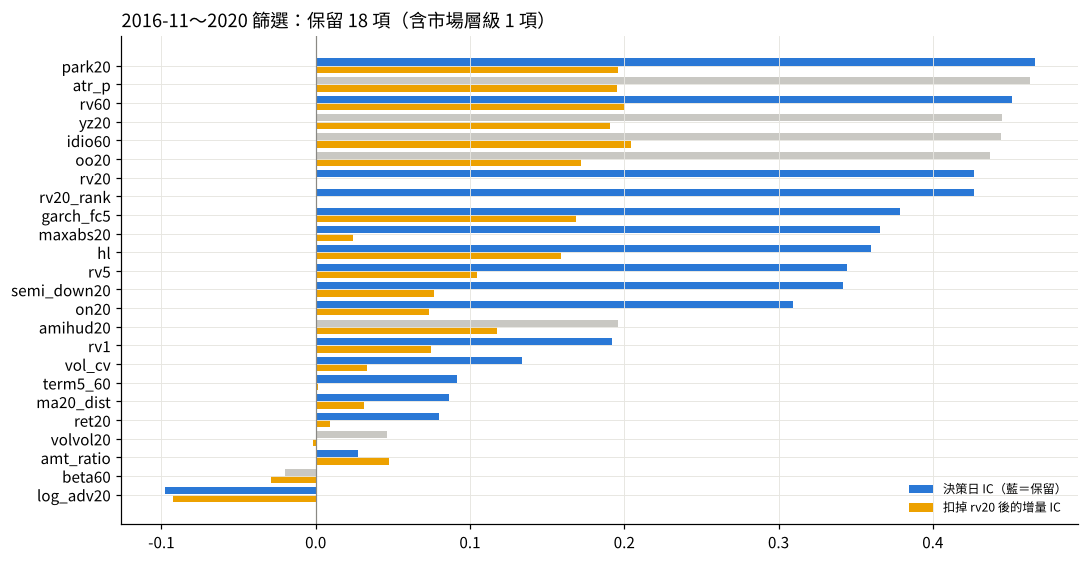

In [7]:
fig, ax = plt.subplots(figsize=(10, 5.2))                    # 圖：決策日 IC 與增量
r = R.loc[SL].sort_values("ic_dec")                          # 個股層級依 IC 排序
y = np.arange(len(r))                                        # 位置
ax.barh(y + .2, r.ic_dec, .38, color=[BLUE if k else "#c9c8c3" for k in r.keep], label="決策日 IC（藍＝保留）")  # IC
ax.barh(y - .2, r.inc_ic.fillna(0), .38, color=YELLOW, label="扣掉 rv20 後的增量 IC")  # 增量
ax.set_yticks(y); ax.set_yticklabels(r.index); ax.axvline(0, color=GREY, lw=.8); ax.legend(frameon=False, fontsize=8, loc="lower right")  # 座標
ax.set_title(f"2016-11～2020 篩選：保留 {len(keep)} 項（含市場層級 {len([k for k in keep if k in DL])} 項）")  # 標題
save(fig, "03b_feature_v2_screen.png")                       # 存圖

## 結論
新組合的特徵名單、各項篩選數字與保留理由寫在 `outputs/notebooks/feature_v2_screen.csv`；
2021 年新舊特徵組比較寫在 `feature_set_comparison_2021.csv`。
正式採用的 v2 清單寫在 `setup.yaml` 的 `features.v2`（篩選結果去掉 rv20_rank：它的橫斷面排名與 rv20 完全相同），
驗證期（2022–2024）的 v1 vs v2 比較見 `outputs/v2/tables/v1_vs_v2_validation.xlsx`。